# 09 — Experimento final

Reconhecimento de categorias de produtos alimentícios a partir de fotografias de embalagens.

O problema é decidir, só pela imagem, a qual categoria da cesta básica a embalagem pertence. O objetivo deste notebook é mostrar o experimento de visão computacional: base real, pré-processamento, transfer learning e comparação entre MobileNetV3-Large e ResNet18.

Os números exibidos abaixo foram gravados por `scripts/run_academic_experiment.py` em 24 de outubro de 2026. Este notebook lê esses arquivos. Ele não retreina os modelos.

In [1]:
import csv
import json
import sys
from pathlib import Path

import torch
from IPython.display import Image, Markdown, display
from PIL import Image as PilImage

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from classification.candidates import load_checkpoint, top_candidates
from classification.transfer import build_transfer_classifier
from preprocessing.transforms import build_eval_transform
from utils.seed import set_seed

SEED = 42
set_seed(SEED)
print("Resultados carregados de uma execução anterior.")
print("Seed registrada:", SEED)
print("Raiz:", ROOT)

Resultados carregados de uma execução anterior.
Seed registrada: 42
Raiz: C:\xampp\htdocs\POS\Disciplina_15\reconhecimento-inteligente-produtos


## 2. Dataset

As fotografias vêm do Open Food Facts, licença CC BY-SA. O catálogo validado tem 37 produtos e 117 imagens tecnicamente aceitas. O experimento usa apenas imagens de frente ou de embalagem. Versos, ingredientes e tabelas nutricionais permanecem no disco, mas saem do treino porque não mostram a face comercial do produto.

A base é pequena de propósito. O estudo é exploratório e vale para um ambiente controlado.

In [2]:
summary = json.loads((ROOT / "results" / "metrics" / "dataset_summary.json").read_text(encoding="utf-8"))
split = json.loads((ROOT / "data" / "splits" / "academico_s42.json").read_text(encoding="utf-8"))
print("Imagens utilizáveis:", summary["imagens_utilizaveis"])
print("Produtos:", summary["produtos"])
print("Categorias representadas:", summary["categorias"])
print("Imagens excluídas:", summary["imagens_excluidas"], summary["motivos_exclusao"])
print("Resolução média:", summary["resolucao_media"])
print("Baixa representatividade:", summary["categorias_com_baixa_representatividade"])
print("Divisão", split["split_id"], split["quantidades"])
print("Limitações:", split["limitacoes"])

Imagens utilizáveis: 77
Produtos: 37
Categorias representadas: 9
Imagens excluídas: 42 {'verso_ou_tabela_nao_e_frente_da_embalagem': 42}
Resolução média: {'largura': 564.9, 'altura': 754.7}
Baixa representatividade: ['Manteiga']
Divisão academico-grupos-s42 {'treino': 54, 'validacao': 12, 'teste': 11}
Limitações: ['Manteiga: 2 grupo(s) de origem. Não há amostra independente para todos os conjuntos.']


## 3. Análise exploratória

Leite UHT e Arroz concentram mais fotos. Manteiga tem duas imagens e dois grupos de origem, então não há amostra independente para treino, validação e teste ao mesmo tempo.

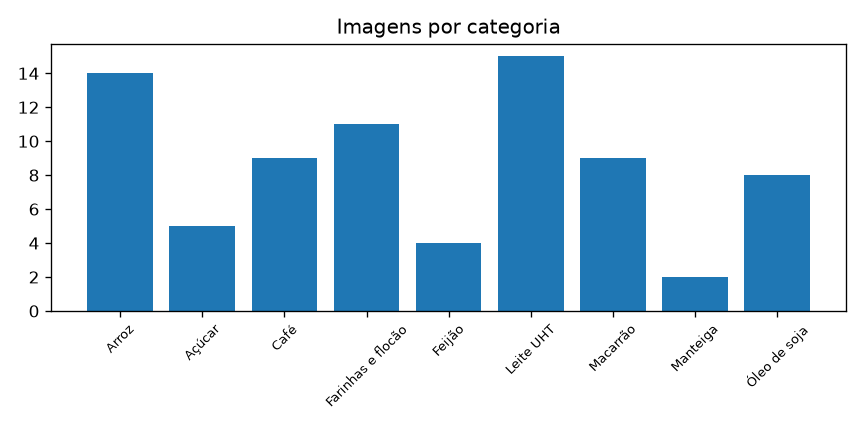

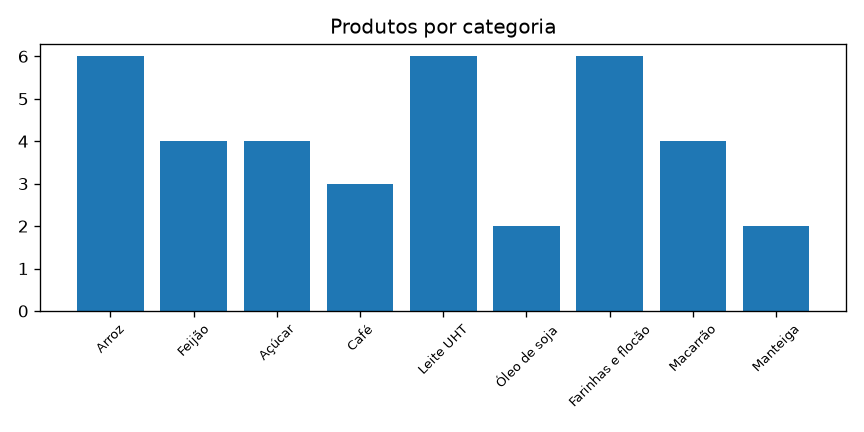

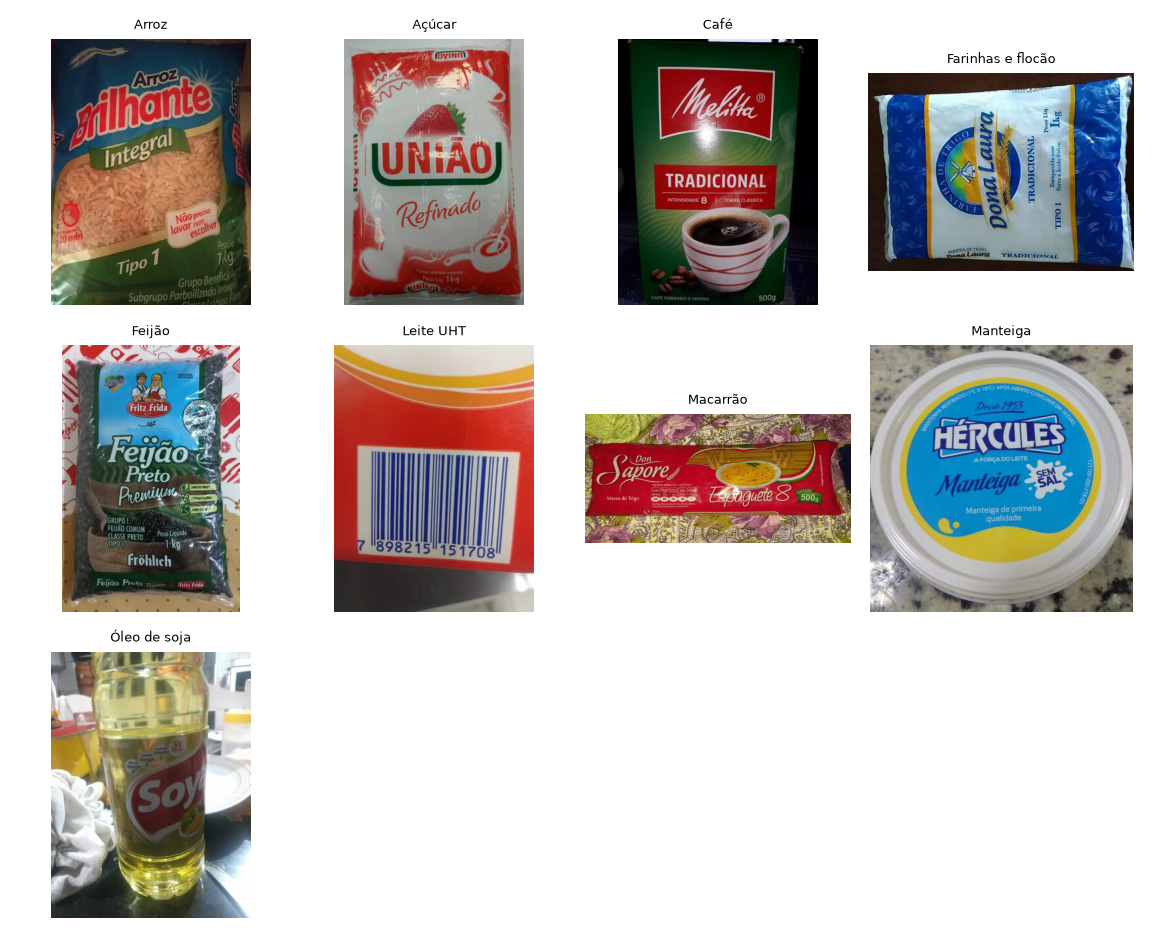

In [3]:
display(Image(filename=str(ROOT / "results" / "figures" / "imagens_por_categoria.png")))
display(Image(filename=str(ROOT / "results" / "figures" / "produtos_por_categoria.png")))
display(Image(filename=str(ROOT / "results" / "figures" / "exemplos_dataset.png")))

## 4. Pré-processamento

Cada foto é convertida para RGB. No treino, a imagem é ampliada para 246 pixels no menor lado, sofre rotação de até 12 graus, alteração leve de brilho e contraste, translação de até 4% e escala entre 0,92 e 1,08. Em seguida vem o recorte central de 224 × 224, a conversão para tensor e a normalização do ImageNet.

Na validação e no teste não há aumento. A imagem vai direto para 224 × 224, tensor e a mesma normalização. O aumento existe só na memória do treino e não cria arquivos novos no manifesto.

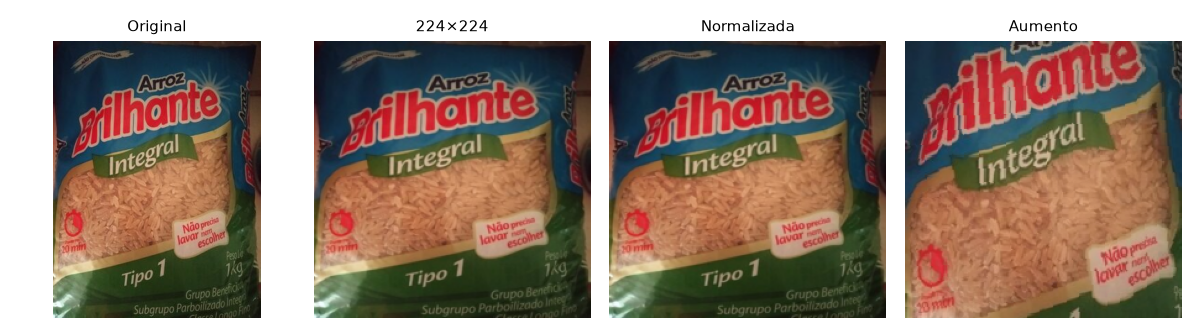

Exemplo: data\brazilian_products\images\BR0001\1.jpg
Tensor de avaliação: (3, 224, 224) torch.float32


In [4]:
display(Image(filename=str(ROOT / "results" / "figures" / "preprocessamento.png")))
sample = next((ROOT / "data" / "brazilian_products").rglob("*.jpg"))
with PilImage.open(sample) as image:
    tensor = build_eval_transform()(image.convert("RGB"))
print("Exemplo:", sample.relative_to(ROOT))
print("Tensor de avaliação:", tuple(tensor.shape), tensor.dtype)

## 5. Transfer learning

Os dois modelos começam com pesos do ImageNet.

MobileNetV3-Large é o modelo principal. ResNet18 é a comparação.

Na etapa A o extrator fica congelado e só a cabeça classificadora é treinada. O número de saídas é o das categorias realmente representadas, nove neste experimento.

Na etapa B as últimas camadas são descongeladas. No MobileNetV3-Large são os três últimos blocos. No ResNet18 é a `layer4`. A taxa de aprendizado da etapa B é 0,0001, dez vezes menor que a da cabeça na etapa A.

O otimizador é AdamW, o lote tem 8 imagens e o teto é de 20 épocas. A parada antecipada observa o F1 macro da validação por 5 épocas. A semente é 42.

A fotografia de demonstração de arroz não entra na escolha do checkpoint. O arquivo escolhido é o de maior F1 de validação. O teste é calculado depois, uma vez.

## 6. Treinamento

A execução completa, em CPU, durou cerca de 140 segundos em 24 de outubro de 2026, já com o download dos pesos do ResNet18. As curvas abaixo são dessa execução.

Execução anterior. Nenhum peso foi atualizado nesta célula.
mobilenet_v3_large etapa A melhor época 20 F1 validação 0.867 segundos 46.1
mobilenet_v3_large etapa B melhor época 3 F1 validação 0.811 segundos 20.8
resnet18 etapa A melhor época 6 F1 validação 0.323 segundos 33.3
resnet18 etapa B melhor época 1 F1 validação 0.222 segundos 25.0


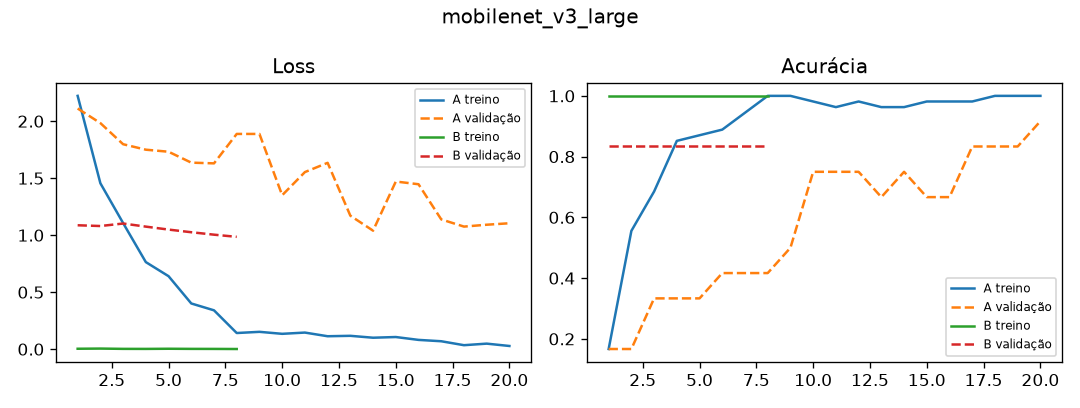

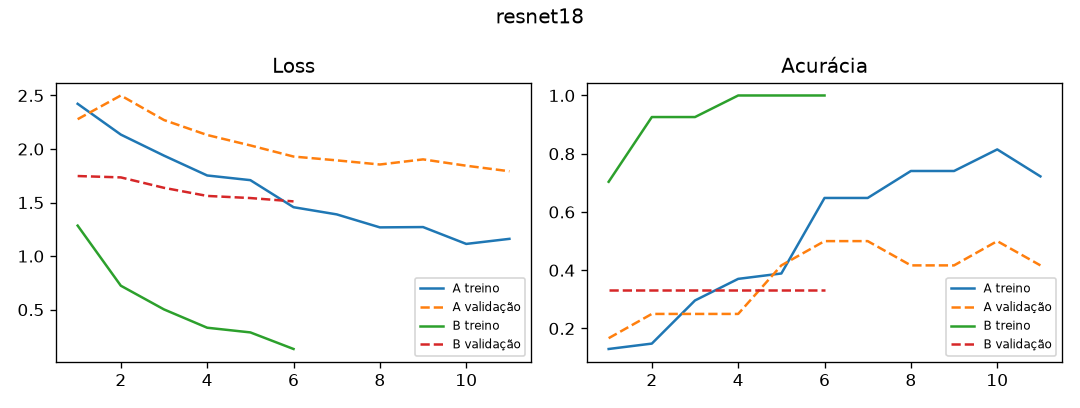

In [5]:
rows = json.loads((ROOT / "results" / "metrics" / "model_comparison.json").read_text(encoding="utf-8"))
print("Execução anterior. Nenhum peso foi atualizado nesta célula.")
for row in rows:
    print(
        row["modelo"],
        "etapa", row["etapa"],
        "melhor época", row["melhor_epoca"],
        "F1 validação", round(row["f1_validacao"], 3),
        "segundos", row["segundos_treino"],
    )
display(Image(filename=str(ROOT / "results" / "figures" / "curvas_mobilenet_v3_large.png")))
display(Image(filename=str(ROOT / "results" / "figures" / "curvas_resnet18.png")))

## 7. Avaliação

Accuracy, precisão, recall e F1 são macro e usam as categorias que aparecem no teste. Manteiga não tem imagem de teste. A matriz de confusão mantém todas as categorias do experimento, inclusive a linha vazia de Manteiga.

O teste tem 11 imagens. Um erro muda a acurácia em cerca de nove pontos percentuais. Esses números descrevem esta divisão, não um desempenho de mercado.

modelo | etapa | accuracy | precision | recall | f1 | treino_s | inferencia_s | parametros
mobilenet_v3_large | A | 0.727 | 0.625 | 0.688 | 0.646 | 46.1 | 0.0294 | 1241609
mobilenet_v3_large | B | 0.545 | 0.333 | 0.438 | 0.375 | 20.8 | 0.0307 | 2991849
resnet18 | A | 0.364 | 0.113 | 0.250 | 0.155 | 33.3 | 0.0431 | 4617
resnet18 | B | 0.455 | 0.354 | 0.500 | 0.396 | 25.0 | 0.0436 | 8398345


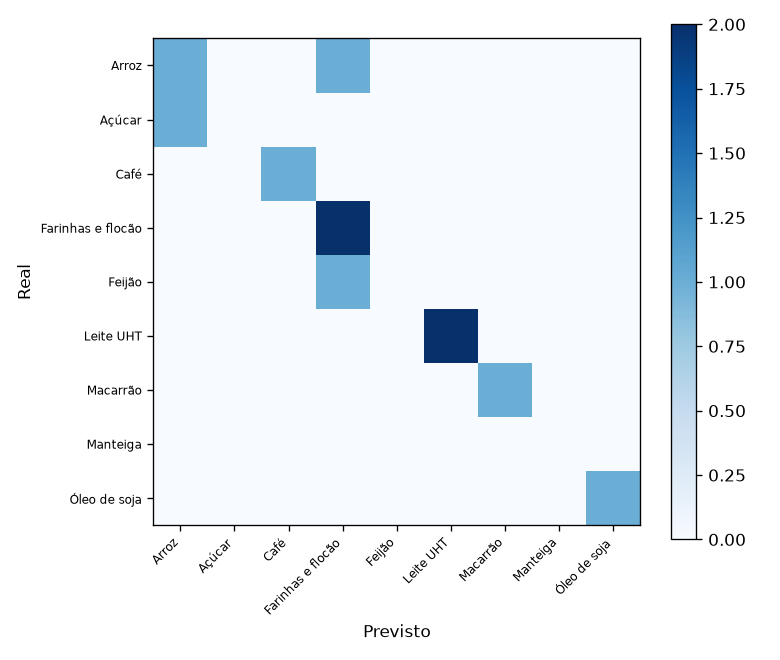

Checkpoint escolhido pela validação: mobilenet_v3_large etapa A
Categorias ausentes no teste: ['Manteiga']


In [6]:
print("modelo | etapa | accuracy | precision | recall | f1 | treino_s | inferencia_s | parametros")
for row in rows:
    print(
        f"{row['modelo']} | {row['etapa']} | {row['accuracy']:.3f} | {row['precision']:.3f} | "
        f"{row['recall']:.3f} | {row['f1']:.3f} | {row['segundos_treino']} | "
        f"{row['segundos_inferencia_media']} | {row['parametros_treinaveis']}"
    )
display(Image(filename=str(ROOT / "results" / "figures" / "matriz_confusao_teste.png")))
chosen = max(rows, key=lambda item: item["f1_validacao"])
print("Checkpoint escolhido pela validação:", chosen["modelo"], "etapa", chosen["etapa"])
print("Categorias ausentes no teste:", chosen["categorias_ausentes_no_teste"])

## 8. Comparação

A comparação usa a mesma divisão `academico-grupos-s42` e o mesmo protocolo. A célula seguinte responde com os valores do arquivo, sem recolocar números à mão.

Maior acurácia no teste: mobilenet_v3_large A 0.727
Maior F1 no teste: mobilenet_v3_large A 0.646
Maior tempo de treino: mobilenet_v3_large A 46.1 s
Menor tempo de inferência: mobilenet_v3_large A 0.0294 s
mobilenet_v3_large variação do F1 de validação na etapa B: -0.056
resnet18 variação do F1 de validação na etapa B: -0.101


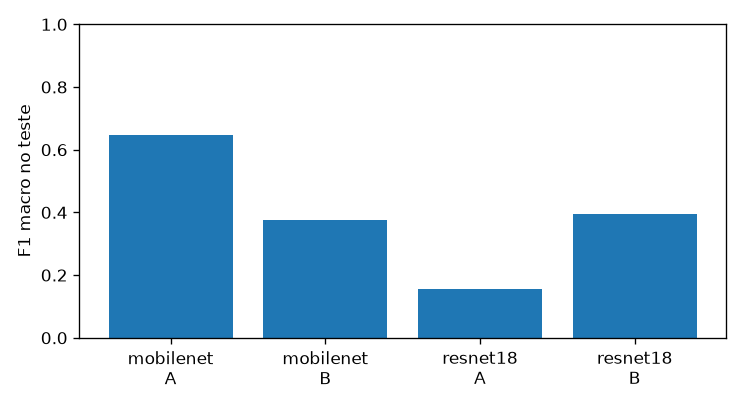

A etapa B não aumentou o F1 de validação em nenhuma das duas arquiteturas. No ResNet18 o F1 de teste subiu enquanto o de validação caiu. Essa discordância fica registrada e não é usada para trocar o checkpoint. Para o ambiente controlado deste projeto, a etapa A do MobileNetV3-Large é a mais adequada: foi a melhor na validação, a mais rápida na inferência e cabe em CPU.

In [7]:
by_acc = max(rows, key=lambda item: item["accuracy"])
by_f1 = max(rows, key=lambda item: item["f1"])
by_time = max(rows, key=lambda item: item["segundos_treino"])
by_speed = min(rows, key=lambda item: item["segundos_inferencia_media"])
print("Maior acurácia no teste:", by_acc["modelo"], by_acc["etapa"], round(by_acc["accuracy"], 3))
print("Maior F1 no teste:", by_f1["modelo"], by_f1["etapa"], round(by_f1["f1"], 3))
print("Maior tempo de treino:", by_time["modelo"], by_time["etapa"], by_time["segundos_treino"], "s")
print("Menor tempo de inferência:", by_speed["modelo"], by_speed["etapa"], by_speed["segundos_inferencia_media"], "s")
for name in ("mobilenet_v3_large", "resnet18"):
    stage_a = next(item for item in rows if item["modelo"] == name and item["etapa"] == "A")
    stage_b = next(item for item in rows if item["modelo"] == name and item["etapa"] == "B")
    delta = stage_b["f1_validacao"] - stage_a["f1_validacao"]
    print(name, "variação do F1 de validação na etapa B:", round(delta, 3))
display(Image(filename=str(ROOT / "results" / "figures" / "comparacao_modelos.png")))
display(Markdown(
    "A etapa B não aumentou o F1 de validação em nenhuma das duas arquiteturas. "
    "No ResNet18 o F1 de teste subiu enquanto o de validação caiu. Essa discordância fica registrada e não é usada para trocar o checkpoint. "
    "Para o ambiente controlado deste projeto, a etapa A do MobileNetV3-Large é a mais adequada: foi a melhor na validação, a mais rápida na inferência e cabe em CPU."
))

## 9. Inferência

A previsão abaixo usa uma imagem do conjunto de teste e o checkpoint `models/brazilian/experiment_best.pt`. Os três maiores escores são as probabilidades softmax.

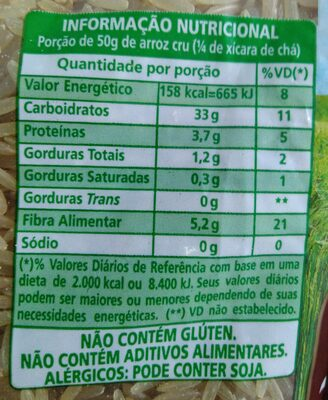

Arquivo de teste: images/BR0003/2.jpg
Categoria real: Arroz
Checkpoint: experiment_best.pt mobilenet_v3_large etapa A
Farinhas e flocão 0.471
Óleo de soja 0.303
Leite UHT 0.086


In [8]:
checkpoint_path = ROOT / "models" / "brazilian" / "experiment_best.pt"
checkpoint = load_checkpoint(checkpoint_path)
labels = [str(label) for label in checkpoint["labels"]]
model = build_transfer_classifier(
    checkpoint["architecture"],
    num_classes=len(labels),
    stage="A",
    pretrained=False,
)
model.load_state_dict(checkpoint["state_dict"])
model.eval()

with (ROOT / "data" / "splits" / "academico_s42_teste.csv").open(encoding="utf-8", newline="") as handle:
    test_rows = list(csv.DictReader(handle))
example = test_rows[0]
image_path = ROOT / "data" / "brazilian_products" / example["arquivo"]
display(Image(filename=str(image_path)))
with PilImage.open(image_path) as image:
    batch = build_eval_transform()(image.convert("RGB")).unsqueeze(0)
with torch.no_grad():
    probabilities = torch.softmax(model(batch), dim=1)[0].tolist()
print("Arquivo de teste:", example["arquivo"])
print("Categoria real:", example["categoria"])
print("Checkpoint:", checkpoint_path.name, checkpoint["architecture"], "etapa", checkpoint["stage"])
for candidate in top_candidates(probabilities, labels, 3):
    print(candidate["rotulo"], round(float(candidate["probabilidade"]), 3))

## 10. Conclusão

O experimento mostra transfer learning de verdade: pesos do ImageNet, cabeça nova e uma etapa complementar de fine-tuning. Nesta base, congelar o extrator do MobileNetV3-Large foi melhor do que descongelar as últimas camadas. O treino chegou a acurácia 1,0 enquanto a validação ficou abaixo disso, sinal de sobreajuste possível num conjunto de 54 imagens de treino.

A diferença entre MobileNetV3-Large e ResNet18 na validação é grande, mas o teste tem 11 fotos. Não cabe tratar 0,73 de acurácia como estimativa estável nem como prontidão comercial.

O que fica demonstrado é o método: pré-processamento, aumento moderado, duas arquiteturas, seleção pela validação e métricas num conjunto separado. A generalização para gôndola, iluminação variável e produtos fora do catálogo não foi medida.